# A6. 구조화 출력과 컨텍스트 엔지니어링

- 영상: [1:04:58 Structured outputs & constrained decoding](https://www.youtube.com/watch?v=Vr1NzH8bT44&t=3898s), [1:10:12 Context engineering & context rot](https://www.youtube.com/watch?v=Vr1NzH8bT44&t=4212s), [1:16:03 Recursive language models](https://www.youtube.com/watch?v=Vr1NzH8bT44&t=4563s)
- 슬라이드: `data/lecture02.pdf` 149–176쪽 [1]
- 읽을거리: [Effective Context Engineering for AI Agents](https://www.anthropic.com/engineering/effective-context-engineering-for-ai-agents) [2] (`data/`에 HTML)

## 목표

1. 금지할 토큰의 logit을 지워서(logit masking) 모델이 **정해진 선택지**나 **정해진 JSON 형식**으로만 답하게 만듭니다.
2. 에이전트의 컨텍스트에 무엇이 들어가는지 보고, 앞부분이 같은 프롬프트는 KV 캐시를 다시 쓸 수 있다는 것과 앞부분을 고치면 그 이득이 사라진다는 것을 잽니다.
3. 글이 길어질수록 모델이 무엇을 놓치는지(context rot) 두 가지 과제로 직접 실험합니다.
4. 긴 컨텍스트를 다루는 방법(압축, 자료를 코드로 다루기)을 그림과 실험으로 봅니다.

**이 노트북이 답하는 질문**: 모델의 답을 프로그램이 믿고 쓸 수 있게 하려면, 그리고 긴 작업에서 모델이 길을 잃지 않게 하려면 무엇을 해야 하나?

모델은 Qwen3-8B(82억 파라미터, 기본 컨텍스트 32,768 토큰 [3])를 생각 끄기(`enable_thinking=False`)로 씁니다. GPU 메모리 약 17 GB가 필요합니다.

문장 끝의 `[번호]`는 맨 아래 **출처** 절의 번호입니다. "이 노트북의 결과"라고 적은 것은 여기서 직접 돌린 실험 결과입니다.

In [1]:
# 그림 도구: 펼치지 않아도 됩니다.
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

plt.rcParams.update({"font.size": 10, "axes.titlesize": 11, "axes.spines.top": False, "axes.spines.right": False})
OI = {"orange": "#E69F00", "sky": "#56B4E9", "green": "#009E73", "yellow": "#F0E442",
      "blue": "#0072B2", "red": "#D55E00", "pink": "#CC79A7", "black": "#000000", "grey": "#BBBBBB"}   # Okabe-Ito


def _box(ax, x, y, w, h, text, color, fs=9.5, tc="black", ec="#555555"):
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.02,rounding_size=0.08",
                                fc=color, ec=ec, lw=1))
    ax.text(x, y, text, ha="center", va="center", fontsize=fs, color=tc)


def _arrow(ax, x0, y0, x1, y1, text=None, fs=8.5):
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle="-|>", color="#444444", lw=1.3))
    if text:
        ax.text((x0 + x1) / 2, (y0 + y1) / 2 + 0.1, text, ha="center", va="bottom", fontsize=fs, color="#444444")


def flow(steps, notes=None, colors=None, ncol=4, title=None, w=2.3, h=0.9, figw=13):
    """steps 를 ncol 개씩 뱀 모양(다음 줄은 오른쪽에서 왼쪽)으로 상자-화살표로 그린다."""
    n = len(steps)
    nrow = (n + ncol - 1) // ncol
    fig, ax = plt.subplots(figsize=(figw, 1.75 * nrow + 0.3))
    pos = []
    for i in range(n):
        r, c = divmod(i, ncol)
        c = c if r % 2 == 0 else ncol - 1 - c
        pos.append((c * 3.2, -r * 1.75))
    for i, ((x, y), s) in enumerate(zip(pos, steps)):
        _box(ax, x, y, w, h, s, colors[i] if colors else OI["sky"])
        if notes and notes[i]:
            ax.text(x, y - h / 2 - 0.08, notes[i], ha="center", va="top", fontsize=8.5, color="#333333")
    for i in range(n - 1):
        (x0, y0), (x1, y1) = pos[i], pos[i + 1]
        if y0 == y1:
            d = 1 if x1 > x0 else -1
            _arrow(ax, x0 + d * w / 2, y0, x1 - d * w / 2, y1)
        else:
            _arrow(ax, x0 + w / 2 + 0.05, y0, x1 + w / 2 + 0.05, y1)
    ax.set_xlim(-w / 2 - 0.2, (ncol - 1) * 3.2 + w / 2 + 0.3)
    ax.set_ylim(-(nrow - 1) * 1.75 - h / 2 - 0.45, h / 2 + 0.15)
    ax.axis("off")
    if title:
        ax.set_title(title)
    fig.tight_layout()
    plt.show()


def draw_mask(tokens, probs, allowed):
    """tokens/probs: 마스크 전 확률이 높은 순, allowed: 허용 토큰 문자열 집합"""
    probs = np.asarray(probs)
    ok = np.array([t in allowed for t in tokens])
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.0), gridspec_kw={"width_ratios": [1.5, 1]})
    x = np.arange(len(tokens))
    ax[0].bar(x, probs, color=[OI["green"] if o else OI["grey"] for o in ok])
    for i, o in enumerate(ok):
        if not o:
            ax[0].text(i, probs[i] * 1.3, "x", ha="center", va="bottom", color=OI["red"], fontsize=11, fontweight="bold")
    ax[0].set_yscale("log")
    ax[0].set_ylim(probs.min() / 3, 3)
    ax[0].set_xticks(x, [repr(t)[1:-1] for t in tokens], rotation=45, ha="right", fontsize=8.5)
    ax[0].set_ylabel("probability before mask (log scale)")
    ax[0].set_title("A. Model's top tokens: grey x = not allowed -> logit set to -inf")
    allowed_idx = np.where(ok)[0]
    p_after = probs[allowed_idx] / probs[allowed_idx].sum() if len(allowed_idx) else []
    ax[1].bar(np.arange(len(allowed_idx)), p_after, color=OI["green"])
    for i, v in enumerate(p_after):
        ax[1].text(i, v + 0.01, f"{v:.2f}", ha="center", va="bottom", fontsize=8.5)
    ax[1].set_xticks(np.arange(len(allowed_idx)), [repr(tokens[i])[1:-1] for i in allowed_idx], fontsize=9)
    ax[1].set_ylim(0, 1.1)
    ax[1].set_ylabel("probability (after mask)")
    ax[1].set_title("B. Only allowed tokens remain")
    fig.tight_layout()
    plt.show()


def draw_json_path(trace, per_row=11):
    rows = [trace[i:i + per_row] for i in range(0, len(trace), per_row)]
    fig, ax = plt.subplots(figsize=(14, 1.15 * len(rows) + 1.0))
    for r, row in enumerate(rows):
        for c, (t, rank) in enumerate(row):
            col = OI["green"] if rank == 0 else OI["orange"]
            _box(ax, c * 1.25, -r * 1.15, 1.12, 0.62, repr(t)[1:-1].replace(" ", chr(183))[:9], col, fs=8.5)
            ax.text(c * 1.25, -r * 1.15 - 0.42, f"rank {rank + 1}", ha="center", va="top", fontsize=7.5, color="#555555")
    ax.text(-0.6, 0.62, "green = the model's own top choice was allowed    orange = higher-ranked tokens broke the format and were skipped    (dot = space)",
            fontsize=9)
    ax.set_xlim(-0.8, per_row * 1.25); ax.set_ylim(-(len(rows) - 1) * 1.15 - 0.75, 0.95)
    ax.axis("off")
    fig.tight_layout()
    plt.show()


def draw_window(parts, window):
    fig, ax = plt.subplots(figsize=(13, 2.3))
    cols = [OI["blue"], OI["sky"], OI["pink"], OI["orange"], OI["red"], OI["green"]]
    left = 0
    for (lab, n), c in zip(parts, cols):
        ax.barh(0, n, left=left, color=c, edgecolor="white")
        if n < 2000:   # 좁은 칸은 이름을 막대 위에
            ax.text(left + n / 2, 0.45, f"{lab.replace(chr(10), ' ')} {n:,}", ha="center", va="bottom", fontsize=8.5)
        else:
            ax.text(left + n / 2, 0, f"{lab}\n{n:,}", ha="center", va="center", fontsize=8.5,
                    color="white" if c in (OI["blue"], OI["red"]) else "black")
        left += n
    ax.barh(0, window - left, left=left, color="#F2F2F2", edgecolor="#BBBBBB")
    ax.text(left + (window - left) / 2, 0, f"free for the answer\n{window - left:,}", ha="center", va="center", fontsize=8.5)
    ax.set_xlim(0, window)
    ax.set_ylim(-0.5, 0.85)
    ax.set_yticks([])
    ax.set_xlabel(f"tokens in one model call (window = {window:,}); ILLUSTRATIVE split")
    ax.spines["left"].set_visible(False)
    fig.tight_layout()
    plt.show()


def draw_prefix(n_prefix, n_q, same, t_full_ms, t_reuse_ms):
    fig, ax = plt.subplots(figsize=(13, 3.0))
    tot = n_prefix + n_q
    wmin = tot * 0.02                                  # 아주 짧은 칸은 보이도록 최소 폭으로 그린다(눈금보다 넓음)
    wq, ws = max(n_q, wmin), max(same, wmin)
    ax.barh(1, n_prefix, color=OI["green"]); ax.barh(1, wq, left=n_prefix, color=OI["orange"], hatch="//", ec="white")
    ax.text(n_prefix / 2, 1, f"same prefix as last call: {n_prefix:,} tokens -> reuse KV cache", ha="center", va="center", fontsize=9)
    ax.text(n_prefix + wq + tot * 0.01, 1, f"new question {n_q} tokens\n{t_reuse_ms:.0f} ms (vs {t_full_ms:.0f} ms from scratch)",
            va="center", fontsize=9)
    ax.barh(0, ws, color=OI["green"], hatch="//", ec="white"); ax.barh(0, tot - same, left=ws, color=OI["red"])
    ax.text(ws + (tot - same) / 2, 0, f"timestamp added at the top: only {same} tokens match -> recompute {tot - same:,} tokens",
            ha="center", va="center", fontsize=9, color="white")
    ax.set_yticks([1, 0], ["append-only", "edit at top"])
    ax.set_xlim(0, tot * 1.35)
    ax.set_xlabel("prompt position (tokens); hatched pieces are drawn wider than scale so they are visible")
    ax.spines["left"].set_visible(False)
    fig.tight_layout()
    plt.show()


def draw_tasks(seed=0):
    rng = np.random.default_rng(seed)
    fig, ax = plt.subplots(1, 2, figsize=(13, 3.2))
    n = 60
    for i in range(n):
        r, c = divmod(i, 15)
        needle = i == 37
        ax[0].add_patch(plt.Rectangle((c, -r), 0.85, 0.7, color=OI["red"] if needle else "#E5E5E5"))
    ax[0].text(37 % 15 + 0.42, -(37 // 15) + 0.35, "code", ha="center", va="center", fontsize=7.5, color="white")
    ax[0].set_title("A. Needle: find ONE sentence among filler", fontsize=10.5)
    lab = rng.random(n) < 0.5
    for i in range(n):
        r, c = divmod(i, 15)
        ax[1].add_patch(plt.Rectangle((c, -r), 0.85, 0.7, color=OI["orange"] if lab[i] else OI["sky"]))
    ax[1].set_title(f"B. Aggregation: count ALL tumor records (orange) -> {lab.sum()}", fontsize=10.5)
    for a in ax:
        a.set_xlim(-0.2, 15); a.set_ylim(-3.4, 0.9); a.axis("off")
    fig.tight_layout()
    plt.show()


def draw_compaction():
    fig, ax = plt.subplots(figsize=(13, 3.4))
    before = [("system", 1.2, OI["blue"]), ("task", 0.6, OI["orange"]), ("tool result 1", 2.4, OI["red"]),
              ("turn", 0.6, OI["orange"]), ("tool result 2", 2.6, OI["red"]), ("turn", 0.6, OI["orange"]),
              ("tool result 3", 2.2, OI["red"]), ("turn", 0.6, OI["orange"])]
    x = 0
    for lab, w, c in before:
        ax.add_patch(plt.Rectangle((x, 1), w, 0.6, color=c, ec="white"))
        ax.text(x + w / 2, 1.3, lab, ha="center", va="center", fontsize=8, color="white" if c != OI["orange"] else "black")
        x += w
    ax.axvline(11.5, ymin=0.45, ymax=0.95, color="black", ls="--", lw=1)
    ax.text(11.6, 1.75, "window limit", fontsize=8.5)
    ax.text(0, 1.85, "before: the context is almost full", fontsize=9.5)
    after = [("system", 1.2, OI["blue"]), ("summary of work so far", 2.2, OI["green"]), ("last turn", 0.6, OI["orange"])]
    x = 0
    for lab, w, c in after:
        ax.add_patch(plt.Rectangle((x, -0.2), w, 0.6, color=c, ec="white"))
        ax.text(x + w / 2, 0.1, lab, ha="center", va="center", fontsize=8, color="white" if c == OI["blue"] else "black")
        x += w
    ax.text(0, 0.65, "after compaction: start a new context with a summary", fontsize=9.5)
    ax.text(4.4, -0.55, "long summary: the window fills up again quickly;   short summary: facts the task needs may be gone",
            fontsize=9, color=OI["red"])
    ax.set_xlim(-0.2, 13.2); ax.set_ylim(-0.9, 2.1); ax.axis("off")
    fig.tight_layout()
    plt.show()


def draw_rlm(n_rec, truth, direct, code, result):
    fig, ax = plt.subplots(figsize=(13, 3.8))
    _box(ax, 0, 1.1, 2.4, 0.8, f"{n_rec:,} records\npasted into the prompt", "#E5E5E5")
    _box(ax, 4.6, 1.1, 1.6, 0.8, "LM", OI["sky"])
    ok = str(truth) in str(direct)
    _box(ax, 7.6, 1.1, 2.2, 0.8, f"answer: {direct}\n(truth {truth})", OI["green"] if ok else OI["red"], tc="white")
    _arrow(ax, 1.2, 1.1, 3.8, 1.1); _arrow(ax, 5.4, 1.1, 6.5, 1.1)
    ax.text(-1.2, 1.7, "A. everything in the context", fontsize=10)
    _box(ax, 0, -0.6, 2.4, 0.9, f"Python REPL\nvariable `records`\n({n_rec:,} items)", OI["yellow"])
    _box(ax, 4.6, -0.6, 1.6, 0.8, "LM", OI["sky"])
    _box(ax, 7.6, -0.6, 2.2, 0.8, f"answer: {result}", OI["green"], tc="white")
    ax.annotate("", xy=(1.2, -0.42), xytext=(3.8, -0.42), arrowprops=dict(arrowstyle="-|>", color="#444444", lw=1.3))
    short = code if len(code) <= 34 else code[:31] + "..."
    ax.text(2.5, -0.32, f"LM writes: {short}", ha="center", va="bottom", fontsize=7.5, family="monospace")
    ax.annotate("", xy=(3.8, -0.78), xytext=(1.2, -0.78), arrowprops=dict(arrowstyle="-|>", color="#444444", lw=1.3))
    ax.text(2.5, -0.88, f"REPL runs it -> {result}", ha="center", va="top", fontsize=8)
    _arrow(ax, 5.4, -0.6, 6.5, -0.6)
    ax.text(-1.2, 0.05, "B. recursive LM idea: data stays outside the context", fontsize=10)
    ax.set_xlim(-1.3, 9.0); ax.set_ylim(-1.4, 2.0); ax.axis("off")
    fig.tight_layout()
    plt.show()

In [2]:
import os, warnings
os.environ["TRANSFORMERS_VERBOSITY"] = "error"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["HF_HUB_VERBOSITY"] = "error"
warnings.filterwarnings("ignore")          # 설치 환경에 따라 나오는 경고 문구를 숨긴다

import copy, json, random, re, time
import pandas as pd
import regex                         # transformers 가 쓰는 패키지. 부분 일치(partial) 검사를 지원한다
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

device = "cuda" if torch.cuda.is_available() else "cpu"
MODEL = "Qwen/Qwen3-8B"
tok = AutoTokenizer.from_pretrained(MODEL)
model = AutoModelForCausalLM.from_pretrained(MODEL, dtype=torch.bfloat16).to(device).eval()
random.seed(0); torch.manual_seed(0)

def sync():
    if device == "cuda":
        torch.cuda.synchronize()

def chat_ids(user, system=None):
    msgs = ([{"role": "system", "content": system}] if system else []) + [{"role": "user", "content": user}]
    text = tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True, enable_thinking=False)
    return tok(text, return_tensors="pt").input_ids.to(device)

@torch.no_grad()
def answer(user, max_new=60, system=None):
    ids = chat_ids(user, system)
    out = model.generate(ids, max_new_tokens=max_new, do_sample=False, temperature=None, top_p=None, top_k=None)
    return tok.decode(out[0, ids.shape[1]:], skip_special_tokens=True).strip()

## 개념 지도

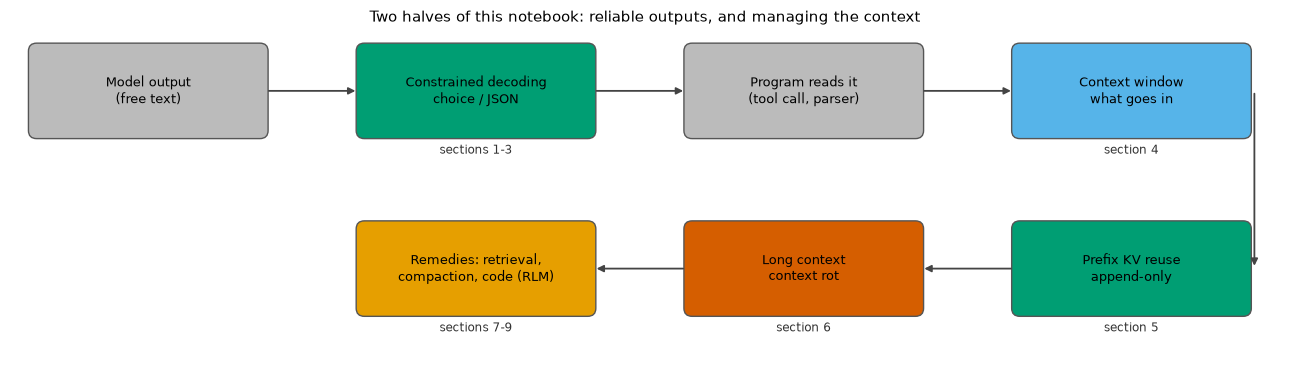

In [3]:
flow(["Model output\n(free text)", "Constrained decoding\nchoice / JSON", "Program reads it\n(tool call, parser)",
      "Context window\nwhat goes in", "Prefix KV reuse\nappend-only", "Long context\ncontext rot",
      "Remedies: retrieval,\ncompaction, code (RLM)"],
     notes=["", "sections 1-3", "", "section 4", "section 5", "section 6", "sections 7-9"],
     colors=[OI["grey"], OI["green"], OI["grey"], OI["sky"], OI["green"], OI["red"], OI["orange"]], ncol=4,
     title="Two halves of this notebook: reliable outputs, and managing the context")

**그림에서 볼 것**
- 위 줄은 **출력** 쪽입니다: 모델의 답을 프로그램이 읽을 수 있게 형식을 강제합니다 [1, 151–159쪽].
- 아래 줄은 **입력** 쪽입니다: 매 호출마다 컨텍스트에 무엇을 넣을지 정하는 일(컨텍스트 엔지니어링) [1, 160–173쪽][2].

## 1. 왜 출력 형식을 강제하나 (슬라이드 151–152쪽)

**한 줄 정의**: 구조화 출력(structured output)은 모델이 정해진 형식(선택지 하나, JSON 등)으로만 답하게 하는 것입니다 [1, 151–153쪽].

**왜 필요한가**: 에이전트는 모델의 답을 사람이 아니라 **프로그램**이 읽습니다. 여러 부품이 이어진 시스템에서는 부품 사이에 "어떤 형식으로 주고받을지"라는 약속이 필요합니다 [1, 152쪽]. "JSON으로 답해"라고 부탁만 하면 대개 지키지만, 설명을 덧붙이거나 다른 키 이름을 쓰면 프로그램이 깨집니다(아래 3절에서 실제로 봅니다).

### 먼저 알아 둘 것: logit과 확률

모델은 다음 토큰마다 어휘 전체(Qwen3는 15만 개 남짓)에 점수 하나씩을 냅니다. 이 점수가 **logit**이고, softmax를 거치면 확률이 됩니다(A1). logit을 $-\infty$로 바꾸면 $e^{-\infty} = 0$이라 그 토큰의 확률이 정확히 0이 되어 절대 뽑히지 않습니다. 이것이 **logit masking**입니다 [4][5].

## 2. 선택지 중 하나로만 답하게 하기

**한 줄 정의**: 토큰을 고를 때마다 "이 토큰을 붙여도 형식에 맞는가"를 검사해서, 맞지 않는 토큰의 logit을 $-\infty$로 만드는 것이 **constrained decoding**입니다 [1, 153쪽][4].

**숫자로 따라가기**: 변이 설명을 주고 `benign`, `pathogenic`, `uncertain` 중 하나로만 답하게 합니다. 선택지마다 토큰열을 만들어 두고, 지금까지 쓴 토큰과 이어질 수 있는 선택지의 다음 토큰만 허용합니다. 첫 걸음에서는 세 선택지의 첫 토큰만 허용됩니다.

In [4]:
question = ("A frameshift deletion in exon 11 of BRCA1 introduces a premature stop codon. "
            "Classify this variant as benign, pathogenic, or uncertain.")
print("부탁만 했을 때:", repr(answer(question, max_new=40)))

FIRST_STEP = {}

@torch.no_grad()
def choose(user, options):
    ids = chat_ids(user)
    opt_ids = [tok(o, add_special_tokens=False).input_ids for o in options]
    out = []
    while True:
        alive = [o for o in opt_ids if o[:len(out)] == out]          # 지금까지와 이어지는 선택지
        done = [o for o in alive if len(o) == len(out)]
        if done:
            return tok.decode(done[0])
        allowed = sorted({o[len(out)] for o in alive})
        logits = model(torch.cat([ids, torch.tensor([out], device=device, dtype=torch.long)], 1) if out else ids).logits[0, -1]
        if not out:
            FIRST_STEP.update(logits=logits.float().cpu(), allowed=allowed)   # 그림용 기록
        mask = torch.full_like(logits, float("-inf"))
        mask[allowed] = 0
        out.append(int((logits + mask).argmax()))                    # 허용된 토큰 중 가장 높은 것

options = ["benign", "pathogenic", "uncertain"]
picked = choose(question, options)
print("강제했을 때:", picked)
assert picked in options

부탁만 했을 때: 'A **frameshift deletion in exon 11 of BRCA1** that introduces a **premature stop codon** is classified as **pathogenic**.\n\n### Explanation:\n\n- **Frames'
강제했을 때: pathogenic


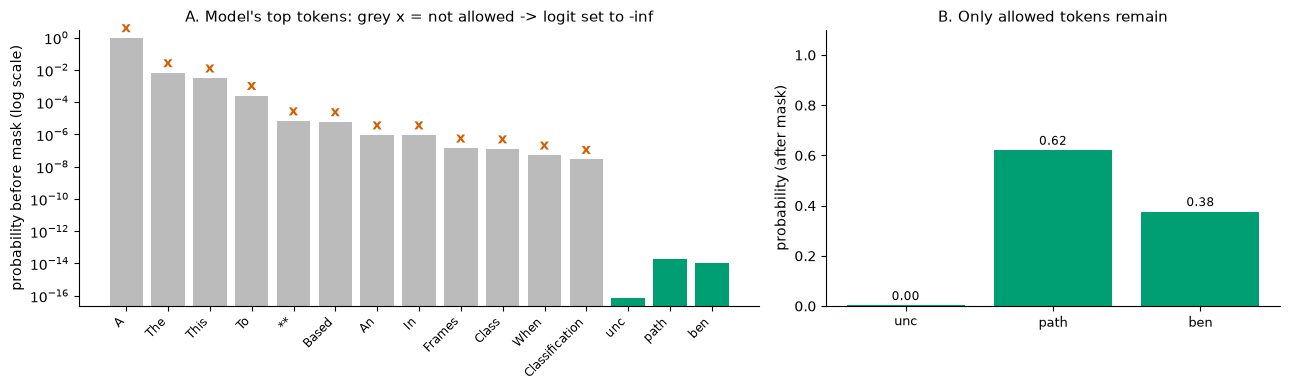

In [5]:
p0 = torch.softmax(FIRST_STEP["logits"], -1)
top = torch.argsort(p0, descending=True)[:12].tolist()
extra = [a for a in FIRST_STEP["allowed"] if a not in top]           # 허용 토큰이 상위 12개 밖이면 덧붙인다
show = top + extra
draw_mask([tok.decode([t]) for t in show], p0[show].numpy(), {tok.decode([a]) for a in FIRST_STEP["allowed"]})

**그림에서 볼 것** (이 노트북의 실제 첫 걸음)
- A: 막대는 모델이 마스크 없이 준 확률이 높은 토큰들입니다(세로축은 로그 눈금이라 아주 작은 확률도 보입니다). 초록이 허용된 토큰(세 선택지의 첫 토큰), 회색 x가 지워질 토큰입니다. 이번 실행에서 모델은 첫 토큰으로 "A"에 거의 모든 확률을 줬고, 허용된 토큰들의 확률은 아주 작았습니다.
- B: 마스크를 씌우면 허용된 토큰들끼리 확률을 다시 나눠 가지고, 그중 가장 높은 초록을 고릅니다.
- **조심할 점**: 이번처럼 허용된 토큰의 원래 확률이 아주 작으면(A 그림에서 약 $10^{-14}$), 그 사이의 나눔(B)은 모델의 판단이라기보다 잡음에 가깝습니다. 이런 경우 강제로 고른 답을 믿지 말고, 먼저 프롬프트에 "한 단어로, 이 중 하나로 답하라"처럼 형식을 적어 모델이 그 형식을 원래부터 높게 치게 만든 다음 강제합니다.
- 한 번 첫 토큰을 고르면 이어질 수 있는 선택지가 줄어들고, 끝까지 가면 반드시 세 선택지 중 하나가 나옵니다.

**직접 바꿔 보기**: `options`에 `"likely pathogenic"`을 더해 보세요. 연습 문제 1번과 이어집니다.

## 3. 정해진 JSON 형식으로만 답하게 하기 (슬라이드 153–154쪽)

**한 줄 정의**: 형식을 정규식(regular expression)이나 문법으로 적고, 토큰마다 "지금까지 쓴 글 + 이 토큰"이 그 형식의 **앞부분이 될 수 있는지** 검사하는 방법입니다. Outlines는 정규식을 유한 상태 기계로 바꾸고 어휘에 대한 색인을 만들어 이 검사를 빠르게 합니다 [4]. **유한 상태 기계**(finite-state machine)는 "지금 어느 단계에 있는지"(상태)와 "다음 글자가 오면 어느 단계로 가는지"(규칙)만으로 이루어진 표입니다. 예를 들어 `{"gene": "`까지 읽은 상태에서는 대문자나 숫자만 다음으로 올 수 있습니다.

**숫자로 따라가기**: 이번 형식은 이렇습니다.

```
{"gene": "<대문자·숫자 1~10자>", "effect": "gain" 또는 "loss", "confidence": <0~100 정수>}
```

`{"ge`는 형식의 앞부분이 될 수 있으니 통과, `{"main`은 될 수 없으니 탈락입니다. `regex` 패키지의 `partial=True`가 바로 이 "앞부분이 될 수 있나" 검사를 합니다.
어휘가 15만 개라 매번 전부 검사하면 느리므로, logit이 높은 토큰부터 차례로 검사해 처음 통과하는 것을 고릅니다(greedy). 실제 라이브러리는 형식을 미리 분석해 허용 토큰 목록을 아주 빠르게 만듭니다 [4][5].

어휘 151,669개


부탁만 했을 때:
 {
  "main_gene": "ERBB2",
  "alteration_type": "gain",
  "confidence": 100
}
→ json.loads 성공



강제했을 때:
 {"gene": "ERBB2", "effect": "gain", "confidence": 90}


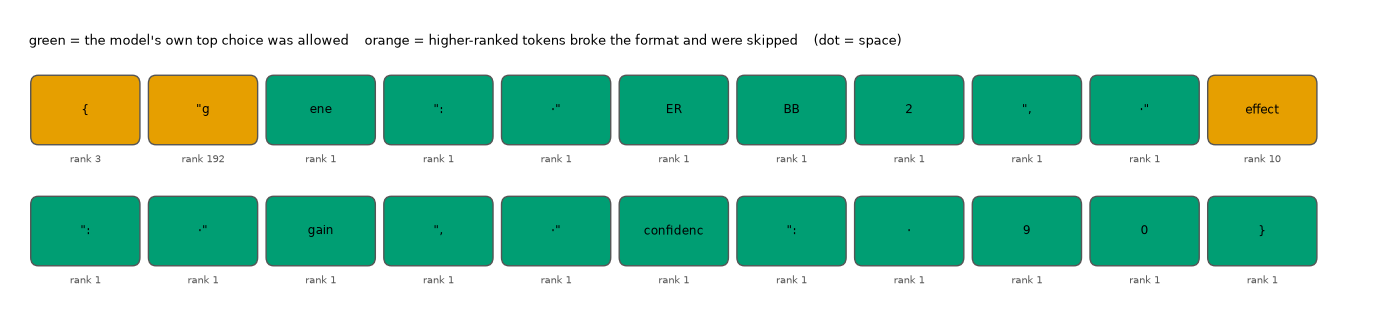

In [6]:
SCHEMA = r'\{"gene": "[A-Z0-9]{1,10}", "effect": "(gain|loss)", "confidence": (100|[1-9]?[0-9])\}'
vocab_text = tok.batch_decode([[i] for i in range(len(tok))])
print(f"어휘 {len(tok):,}개")
assert regex.fullmatch(SCHEMA, '{"ge', partial=True) and not regex.fullmatch(SCHEMA, '{"main', partial=True)

def can_continue(s):
    return regex.fullmatch(SCHEMA, s, partial=True) is not None

JSON_TRACE = []

@torch.no_grad()
def constrained_json(user, max_steps=60):
    ids = chat_ids(user)
    out = model(ids, use_cache=True)
    cache, logits, text = out.past_key_values, out.logits[0, -1], ""
    JSON_TRACE.clear()
    for _ in range(max_steps):
        for rank, t in enumerate(torch.argsort(logits, descending=True).tolist()):
            if t < len(vocab_text) and vocab_text[t] and can_continue(text + vocab_text[t]):   # 빈 토큰은 건너뛴다
                break
        JSON_TRACE.append((vocab_text[t], rank))
        text += vocab_text[t]
        if regex.fullmatch(SCHEMA, text):
            return text
        out = model(torch.tensor([[t]], device=device), past_key_values=cache, use_cache=True)
        cache, logits = out.past_key_values, out.logits[0, -1]
    raise RuntimeError("형식을 끝내지 못함: " + text)

task = ("Report the main gene, whether the alteration is a gain or loss of function, and your confidence (0-100). "
        "Text: 'The tumour carries a focal high-level amplification of ERBB2.' Reply in JSON.")
free = answer(task, max_new=80)
print("부탁만 했을 때:\n", free)
try:
    json.loads(free); print("→ json.loads 성공")
except json.JSONDecodeError as e:
    print("→ json.loads 실패:", e)

forced = constrained_json(task)
print("\n강제했을 때:\n", forced)
obj = json.loads(forced)
assert obj["effect"] in ("gain", "loss") and 0 <= obj["confidence"] <= 100 and re.fullmatch(r"[A-Z0-9]{1,10}", obj["gene"])
draw_json_path(JSON_TRACE)

**그림에서 볼 것** (이 노트북의 실제 생성 과정)
- 칸 하나가 고른 토큰 하나입니다. 아래 `rank`는 그 토큰이 모델의 원래 순위에서 몇 번째였는지입니다.
- 초록(rank 1)은 모델이 원래 가장 좋아한 토큰이 형식에도 맞아서 그대로 쓴 것, 주황은 더 높은 순위 토큰들이 형식을 깨서 건너뛰고 고른 것입니다.
- 형식은 **항상** 맞습니다. 다만 형식만 보장할 뿐, 내용(유전자 이름, gain/loss 판단)이 맞는지는 모델의 실력에 달려 있습니다.
- "부탁만 했을 때"의 답은 JSON으로는 읽히지만 키 이름이 우리가 정한 것(`gene`, `effect`)과 다를 수 있습니다. 프로그램이 `obj["gene"]`을 찾으면 그때 깨집니다.

같은 생각이 여러 곳에 있습니다.

- **도구 호출**(tool calling): 모델이 도구 이름과 인자를 구조화된 형식으로 내면 프로그램이 그 함수를 실행합니다 [1, 159쪽].
- **DSPy signature**: 입력과 출력 필드를 선언하면 프롬프트와 파싱을 대신 만들어 줍니다 [1, 155–156쪽].
- **분류기**: 답이 몇 개 중 하나라면 임베딩 위에 작은 분류 층을 학습해 생성 자체를 없애기도 합니다 [1, 157–158쪽].

## 4. 컨텍스트 창과, 그 안에 들어가는 것 (슬라이드 160–162쪽)

**한 줄 정의**: **컨텍스트 창**(context window)은 모델이 한 번 호출될 때 읽을 수 있는 최대 토큰 수입니다. Qwen3-8B는 기본 32,768 토큰입니다 [3]. 에이전트의 컨텍스트에는 시스템 프롬프트, 대화 기록, 기억, 도구 결과, 첨부 파일이 들어갑니다 [1, 162쪽].

**왜 필요한가**: 창의 크기는 정해져 있고, 넣는 것마다 자리를 차지합니다. 모델이 쓸 수 있는 "주의(attention)"에도 한계가 있어서, 토큰이 늘수록 하나하나에 덜 집중하게 됩니다 [2]. **컨텍스트 엔지니어링**은 원하는 결과를 낼 가능성이 가장 높은, 가장 작은 고신호 토큰 묶음을 찾는 일입니다 [2].

**숫자로 따라가기**: 아래 나눔은 **설명을 위해 지어낸 예시**입니다. 도구 설명이 1만 토큰을 넘으면(아래 5절의 실험이 실제로 11,000여 토큰) 질문을 하기도 전에 창의 3분의 1을 씁니다.

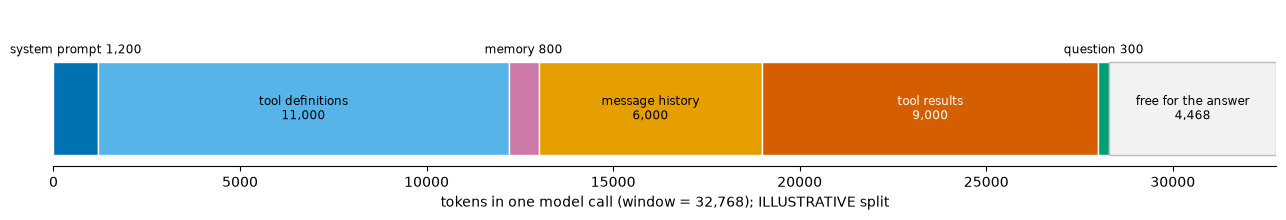

In [7]:
draw_window([("system\nprompt", 1200), ("tool definitions", 11000), ("memory", 800), ("message history", 6000),
             ("tool results", 9000), ("question", 300)], 32768)

**그림에서 볼 것**
- 색 칸이 이번 호출에 넣은 것, 회색이 답을 쓸 자리입니다. 도구 결과(빨강)는 작업이 진행될수록 계속 늘어납니다.
- 무엇을, 어떤 순서로, 얼마나 넣을지가 컨텍스트 엔지니어링입니다. 정답은 하나가 아니라 실험으로 정합니다 [1, 165쪽, 170쪽].

## 5. 앞부분을 고정하면 KV 캐시를 다시 쓴다 (슬라이드 168–169쪽)

**한 줄 정의**: 앞부분이 똑같은 프롬프트는 그 부분의 K, V도 똑같으므로(A5), 이전 호출의 KV 캐시를 재사용하고 새로 붙은 부분만 계산할 수 있습니다(prefix caching) [1, 168–169쪽].

**왜 필요한가**: 반대로 앞부분을 한 글자라도 고치면 그 뒤의 K, V가 전부 달라져 처음부터 다시 계산해야 합니다. 그래서 "뒤에 붙이기만 하고 앞은 고치지 않기"가 기본 규칙입니다 [1, 168쪽]. 상용 API의 프롬프트 캐시도 캐시된 부분까지 **100% 똑같아야** 맞고 [6], 캐시에서 읽은 입력은 기본 입력보다 훨씬 쌉니다(Anthropic 가격표 기준 대부분 모델은 캐시 읽기가 기본 입력의 10%이고, Claude Fable 5.2 등 일부 모델은 2.5%입니다. 예: Fable 5.2 기본 입력 $8/MTok, 캐시 읽기 $0.20/MTok) [7].

**숫자로 따라가기**: 1만 토큰이 넘는 도구 설명서를 시스템 프롬프트로 두고, (1) 처음부터 계산, (2) 저장해 둔 캐시 재사용, (3) 맨 위에 현재 시각 한 줄을 넣었을 때 재사용할 수 있는 앞부분 길이를 잽니다.

앞부분 11219 토큰 + 질문 23 토큰


처음부터 계산 1136 ms,  캐시 재사용 62 ms  (18배)
두 방법의 다음 토큰: 'run' 'run'
맨 위에 시각 한 줄을 넣은 뒤 재사용할 수 있는 앞부분: 3 토큰 / 11219 토큰


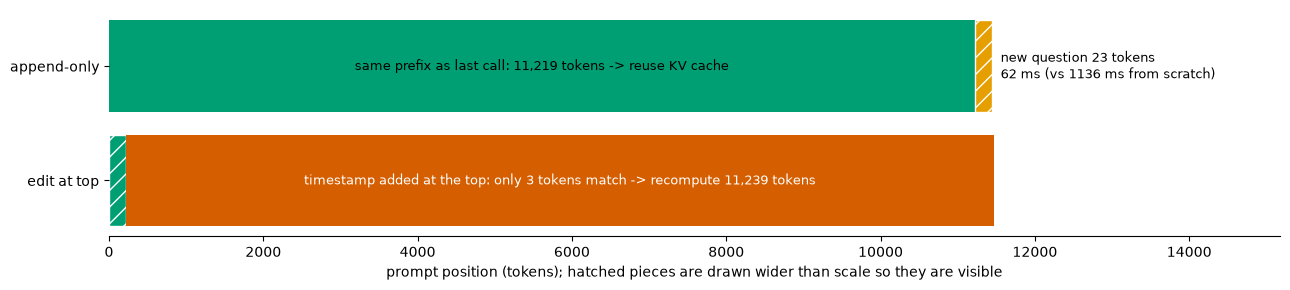

In [8]:
tools_doc = "\n".join(
    f"Tool {i}: run_{w}(sample_id, threshold={i % 7}) runs the {w} analysis on one sample and returns a table of results with columns id, value, flag."
    for i, w in enumerate(["purity", "ploidy", "cnv", "sv", "snv", "indel", "signature", "hrd", "msi", "tmb"] * 30)
)
system = "You are a genomics analysis agent. Available tools:\n" + tools_doc
q = "Which tool estimates tumour purity? Reply with the tool name only."
full_text = tok.apply_chat_template([{"role": "system", "content": system}, {"role": "user", "content": q}],
                                    tokenize=False, add_generation_prompt=True, enable_thinking=False)
split = full_text.index(q)                                 # 질문 앞까지가 "늘 같은 앞부분"
prefix_ids = tok(full_text[:split], add_special_tokens=False, return_tensors="pt").input_ids.to(device)
question_ids = tok(full_text[split:], add_special_tokens=False, return_tensors="pt").input_ids.to(device)
full_ids = torch.cat([prefix_ids, question_ids], 1)
print(f"앞부분 {prefix_ids.shape[1]} 토큰 + 질문 {question_ids.shape[1]} 토큰")

with torch.no_grad():
    model(full_ids, logits_to_keep=1); sync()              # 예열
    t0 = time.perf_counter(); full_logits = model(full_ids, logits_to_keep=1).logits[0, -1]; sync(); t_full = time.perf_counter() - t0

    prefix_cache = model(prefix_ids, use_cache=True, logits_to_keep=1).past_key_values   # 지난 호출에서 저장해 둔 캐시라고 생각
    model(question_ids, past_key_values=copy.deepcopy(prefix_cache), use_cache=True, logits_to_keep=1); sync()   # 예열
    c = copy.deepcopy(prefix_cache); sync()
    t0 = time.perf_counter(); reuse_logits = model(question_ids, past_key_values=c, use_cache=True, logits_to_keep=1).logits[0, -1]; sync(); t_reuse = time.perf_counter() - t0

print(f"처음부터 계산 {t_full * 1e3:.0f} ms,  캐시 재사용 {t_reuse * 1e3:.0f} ms  ({t_full / t_reuse:.0f}배)")
print("두 방법의 다음 토큰:", repr(tok.decode(full_logits.argmax())), repr(tok.decode(reuse_logits.argmax())))
assert full_logits.argmax() == reuse_logits.argmax()

edited = chat_ids(q, system="Current time: 2026-11-13 10:42:07\n" + system)[0]
same = 0
while same < min(len(edited), prefix_ids.shape[1]) and edited[same] == prefix_ids[0, same]:
    same += 1
print(f"맨 위에 시각 한 줄을 넣은 뒤 재사용할 수 있는 앞부분: {same} 토큰 / {prefix_ids.shape[1]} 토큰")
assert same < 10
draw_prefix(prefix_ids.shape[1], question_ids.shape[1], same, t_full * 1e3, t_reuse * 1e3)

**그림에서 볼 것** (이 노트북의 결과)
- 위 줄: 앞부분(초록)이 지난 호출과 같으면 질문(주황)만 계산하면 됩니다. 시간이 처음부터 계산할 때의 몇 분의 1로 줄고, 다음 토큰도 똑같이 나옵니다.
- 아래 줄: 맨 위에 시각 한 줄을 넣자 채팅 형식의 시작 표시 몇 토큰만 같고 나머지(빨강)는 전부 다시 계산해야 합니다.
- 그래서 바뀌는 정보(시각, 최근 결과)는 컨텍스트의 **뒤쪽**에 둡니다.

## 6. context rot: 다 넣으면 왜 안 되나 (슬라이드 163–164쪽)

**한 줄 정의**: 컨텍스트의 토큰이 늘수록 모델이 그 안의 정보를 정확히 꺼내 쓰는 능력이 떨어지는 현상입니다 [2].

**왜 필요한가**: "창이 32k니까 32k를 다 넣어도 된다"고 생각하기 쉽습니다. 그런데 창의 크기와, 그 안을 **얼마나 잘 쓰는지**는 다릅니다.

과제의 종류에 따라 다르게 무너집니다. 두 과제를 길이를 늘려 가며 비교합니다.

- **바늘 찾기**(needle in a haystack): 긴 잡담 속 한 곳에 "냉동고 B의 비밀번호는 ○○○○"라는 문장을 숨기고 물어봅니다. 한 군데만 찾으면 됩니다. 많은 모델이 기본 바늘 찾기는 거의 완벽하게 하지만, 더 어려운 과제에서는 길이가 늘수록 크게 떨어진다는 보고가 있습니다 [8].
- **세기**(aggregation): "샘플 S0123은 tumor/normal로 표시됨" 기록을 길이에 맞춰 수백~수천 개 넣고, tumor가 몇 개인지 묻습니다. 전부를 훑어 합쳐야 합니다. 슬라이드의 OOLONG이 이런 과제를 모은 벤치마크이고, 최신 대형 모델들도 128K 길이에서 50% 미만이었다고 보고합니다 [9].

**숫자로 따라가기**: 기록 60개 중 tumor를 세는 일은 60개를 하나도 빠짐없이 보고 더해야 합니다. 바늘 찾기는 60개 중 하나만 알아보면 됩니다.

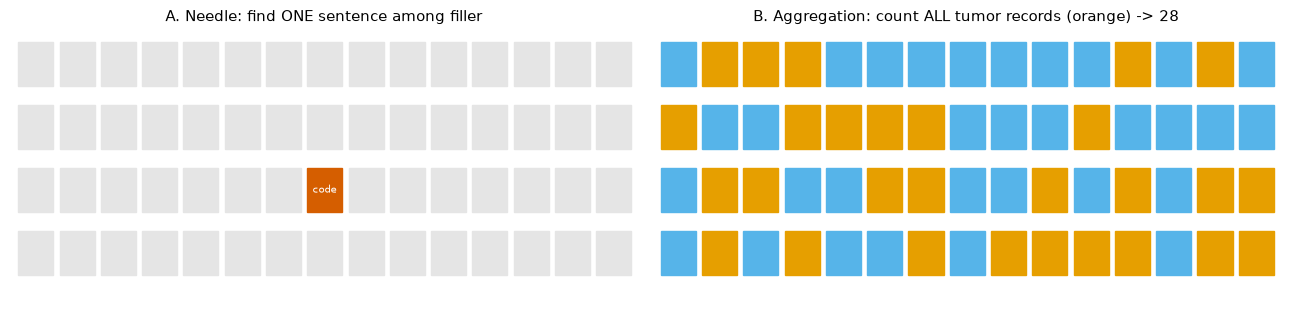

In [9]:
draw_tasks()

**그림에서 볼 것**
- A: 바늘(빨강)은 하나뿐입니다. 나머지는 무시해도 됩니다.
- B: 주황(tumor)을 전부 세야 합니다. 하나라도 빠뜨리거나 두 번 세면 틀립니다. 길이가 늘수록 빠뜨릴 기회가 늘어납니다.

In [10]:
FILLER = [
    "The sequencing run finished overnight and the quality report looked normal.",
    "Reagent lots were logged in the shared spreadsheet before the meeting.",
    "The centrifuge in room 3 was serviced last week and is working again.",
    "Several samples were re-labelled after the freezer inventory check.",
    "The analysis pipeline was updated to the latest release of the aligner.",
    "A reminder was sent about the journal club scheduled for Thursday.",
    "Library preparation took longer than expected because of a pipette issue.",
    "The coverage plots were shared with the clinical team for review.",
]

FILL_LEN = {s: len(tok(" " + s, add_special_tokens=False).input_ids) for s in FILLER}

def haystack(n_tokens, rng):
    out, n = [], 0
    while n < n_tokens:
        s = rng.choice(FILLER); out.append(s); n += FILL_LEN[s]
    return out

@torch.no_grad()
def ask(context, q, max_new=12):
    return answer(context + "\n\n" + q, max_new=max_new)

LENGTHS = [1000, 4000, 8000, 16000, 30000]
DEPTHS = [0.0, 0.25, 0.5, 0.75, 1.0]
rows = []
t0 = time.time()
for L in LENGTHS:
    for dpt in DEPTHS:
        for rep in range(2):
            rng = random.Random(L * 10 + int(dpt * 4) * 2 + rep)
            code = rng.randint(1000, 9999)
            hs = haystack(L, rng)
            hs.insert(int(dpt * len(hs)), f"The access code for freezer B is {code}.")
            reply = ask(" ".join(hs), "What is the access code for freezer B? Reply with the number only.")
            rows.append({"length": L, "depth": dpt, "correct": str(code) in reply})
needle = pd.DataFrame(rows)
print(f"바늘 찾기 {len(needle)}번, {time.time() - t0:.0f}초, 전체 정답률 {needle.correct.mean():.2f}")

바늘 찾기 50번, 75초, 전체 정답률 1.00


In [11]:
def make_records(n_tokens, rng):
    recs, n = [], 0
    while n < n_tokens:
        sid, lab = f"S{rng.randint(0, 99999):05d}", rng.choice(["tumor", "normal"])
        line = f"Sample {sid} was labelled {lab}."
        recs.append((sid, lab)); n += len(tok(line, add_special_tokens=False).input_ids) + 1
    return recs

COUNT_LENGTHS = [250, 500, 1000, 4000, 16000, 30000]
rows = []
t0 = time.time()
for L in COUNT_LENGTHS:
    for rep in range(3):
        rng = random.Random(1000 + L + rep)
        recs = make_records(L, rng)
        truth = sum(lab == "tumor" for _, lab in recs)
        reply = ask(" ".join(f"Sample {s} was labelled {l}." for s, l in recs),
                    "How many samples were labelled tumor? Reply with the number only.")
        m = re.search(r"\d+", reply.replace(",", ""))
        pred = int(m.group()) if m else None
        rows.append({"length": L, "records": len(recs), "truth": truth, "pred": pred,
                     "correct": pred == truth, "rel_error": abs(pred - truth) / truth if pred is not None else 1.0})
count = pd.DataFrame(rows)
print(f"세기 {len(count)}번, {time.time() - t0:.0f}초")
display(count)

세기 18번, 19초


,length,records,truth,pred,correct,rel_error
0,250,21,7,12,False,0.714286
1,250,21,8,14,False,0.750000
2,250,21,4,4,True,0.000000
3,500,42,17,30,False,0.764706
4,500,42,25,43,False,0.720000
5,500,42,19,27,False,0.421053
6,1000,84,49,53,False,0.081633
7,1000,84,47,100,False,1.127660
8,1000,84,43,53,False,0.232558
9,4000,334,153,103,False,0.326797


length,1000,4000,8000,16000,30000
depth,,,,,
0.00,1.0,1.0,1.0,1.0,1.0
0.25,1.0,1.0,1.0,1.0,1.0
0.50,1.0,1.0,1.0,1.0,1.0
0.75,1.0,1.0,1.0,1.0,1.0
1.00,1.0,1.0,1.0,1.0,1.0


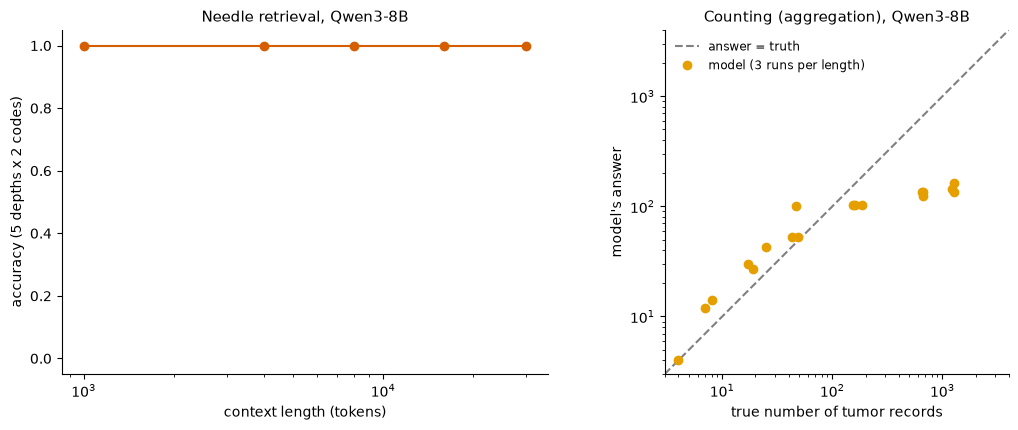

In [12]:
display(needle.pivot_table(index="depth", columns="length", values="correct", aggfunc="mean"))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
nd = needle.groupby("length").correct.mean()
axes[0].plot(nd.index, nd.values, "o-", color=OI["red"])
axes[0].set_xscale("log"); axes[0].set_ylim(-0.05, 1.05)
axes[0].set_xlabel("context length (tokens)"); axes[0].set_ylabel("accuracy (5 depths x 2 codes)")
axes[0].set_title("Needle retrieval, Qwen3-8B")

lim = [3, 4000]
axes[1].plot(lim, lim, "--", c="gray", label="answer = truth")
axes[1].loglog(count.truth, count.pred, "o", color=OI["orange"], label="model (3 runs per length)")
axes[1].legend(loc="upper left", fontsize=8.5, frameon=False)
axes[1].set_xlim(lim); axes[1].set_ylim(lim); axes[1].set_aspect("equal")
axes[1].set_xlabel("true number of tumor records"); axes[1].set_ylabel("model's answer")
axes[1].set_title("Counting (aggregation), Qwen3-8B")
plt.tight_layout(); plt.show()

assert needle.correct.mean() > count[count.length >= 4000].correct.mean()             # 하나 찾기가 전부 세기보다 쉽다
assert count[count.length == 30000].rel_error.mean() > count[count.length == 1000].rel_error.mean()   # 길수록 더 틀린다

**그림에서 볼 것** (이 노트북의 결과)
- 왼쪽: 바늘 찾기는 이 모델과 이 과제에서 30k 토큰까지 거의 다 맞혔습니다. 위의 표를 보면 바늘을 앞, 가운데, 뒤 어디에 두어도 차이가 없었습니다. 정보가 가운데 있을 때 성능이 떨어진다는 보고 [10]가 있지만, 이번 실험처럼 쉬운 과제에서는 그 차이가 드러나지 않을 수 있습니다.
- 오른쪽: 점이 회색 선(정답) 위에 있으면 맞힌 것입니다. 짧은 목록에서는 오히려 많게 세는 경우가 많고(점이 선 위), 길어질수록 모델의 답이 일정한 크기에서 더 커지지 않아 적게 세게 되며 점이 선 아래로 점점 멀어집니다.
- 결론: **전부를 훑어 합쳐야 하는 과제**는 컨텍스트가 길어질수록 무너집니다. 도구 결과를 통째로 쌓아 두고 "다 들어 있으니 알아서 하겠지"라고 기대하면 안 됩니다.

## 7. 실전 규칙 (슬라이드 165–171쪽)

| 규칙 | 뜻 | 출처 |
|---|---|---|
| 군더더기 빼기 | 도구는 꼭 필요한 몇 개만. 도구 설명도 컨텍스트를 먹는다 | [1, 166쪽] |
| 필요할 때 꺼내 오기 | 전부 미리 넣지 말고, 파일 경로 같은 가벼운 참조만 들고 있다가 필요할 때 도구로 불러옴("just in time") | [1, 167쪽][2] |
| 뒤에 붙이기만 | 앞부분을 고치지 않아 KV 캐시를 살림 (5절) | [1, 168–169쪽] |
| 실험으로 정하기 | 무엇을 넣고 뺄지는 평가 세트를 만들어 숫자로 비교 | [1, 170쪽] |
| 압축(compaction) | 너무 길어지면 요약해서 새 컨텍스트를 시작 (8절) | [1, 171쪽][2] |

## 8. 압축(compaction)

**한 줄 정의**: 대화가 컨텍스트 창 한계에 가까워지면 지금까지의 내용을 요약하고, 그 요약으로 새 컨텍스트를 시작하는 것입니다 [2].

**왜 필요한가**: 긴 작업에서는 도구 결과와 대화가 계속 쌓여 결국 창이 찹니다. 6절에서 본 것처럼 창이 차기 전에도 길이가 길수록 모델이 정보를 잘 못 씁니다.

**숫자로 따라가기**: 도구 결과 3개가 각각 수천 토큰이고 대화가 이어지면, 창의 대부분이 이미 쓴 도구 결과입니다. 이미 처리한 도구 결과의 원문은 다시 볼 필요가 없는 경우가 많아, 원문을 지우는 것(tool result clearing)이 가장 가벼운 압축입니다 [2].

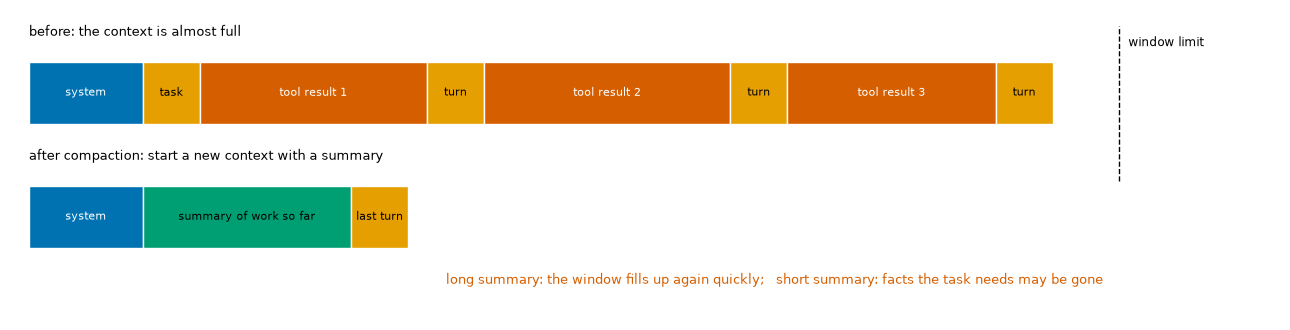

In [13]:
draw_compaction()

**그림에서 볼 것**
- 위: 도구 결과(빨강)가 창을 거의 다 차지했습니다.
- 아래: 시스템 프롬프트와 "지금까지 한 일의 요약", 마지막 대화만 남기고 새로 시작합니다.
- 핵심 결정은 **무엇을 남길지**입니다. 너무 많이 남기면 곧 다시 압축해야 하고, 너무 많이 버리면 작업에 필요한 내용을 잃습니다 [1, 171쪽].

## 9. 다른 생각: 자료를 컨텍스트 밖 변수로 두기 (recursive language model, 슬라이드 172–173쪽)

**한 줄 정의**: 긴 자료를 프롬프트에 넣지 않고 **외부 환경**(파이썬 REPL의 변수)에 두고, 모델이 그 자료를 다루는 코드를 써서 필요한 결과만 받아 보는 방식입니다. 필요하면 자료의 일부에 대해 자기 자신(또는 다른 모델)을 다시 부릅니다 [11][12].

**왜 필요한가**: 6절에서 본 것처럼 "전부 읽고 합치기"는 길이가 길면 무너집니다. 세기, 합치기는 코드가 정확히 합니다.

**숫자로 따라가기**: 위 세기 과제의 가장 긴 경우(약 30k 토큰, 기록 2,500개)를 두 방법으로 풉니다. 모델에게는 변수의 모양만 알려 줍니다.

**REPL**(read–eval–print loop)은 코드를 한 줄 입력하면 바로 실행하고 결과를 보여 주는 대화형 실행 환경입니다. 터미널에서 `python`만 입력하면 뜨는 화면이 그것입니다 [13].

모델이 쓴 코드를 실행하므로, 여기서는 쓸 수 있는 함수를 `sum`, `len`으로만 제한한 식(expression) 하나만 받습니다. 다만 `__builtins__`를 줄이는 것은 보안 장치가 아닙니다. 파이썬 객체의 내부 속성을 타고 들어가 우회할 수 있습니다. 믿을 수 없는 코드는 반드시 격리된 환경(sandbox)에서 실행해야 합니다.

기록 2500개, 정답 1287
전부 넣고 물었을 때: 163
코드를 쓰게 했을 때: sum(1 for record in records if record[1] == 'tumor')  →  1287


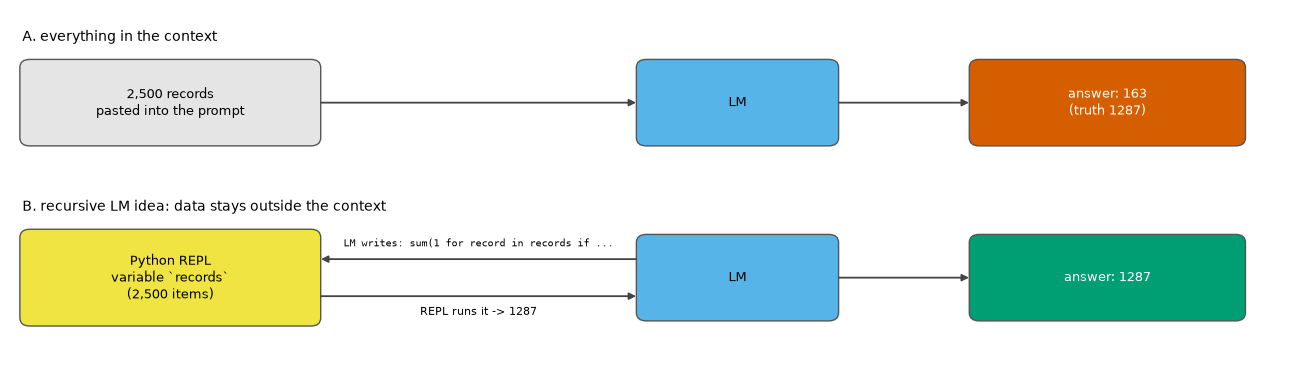

In [14]:
rng = random.Random(7)
records = make_records(30000, rng)
truth = sum(lab == "tumor" for _, lab in records)
direct = ask(" ".join(f"Sample {s} was labelled {l}." for s, l in records),
             "How many samples were labelled tumor? Reply with the number only.")
code = answer("A Python list named `records` holds (sample_id, label) tuples, e.g. ('S00042', 'tumor'). "
              "Write ONE Python expression that returns how many records have the label 'tumor'. "
              "You may only use the functions sum and len. Reply with the expression only, no code fences.", max_new=60)
code = code.strip().strip("`").removeprefix("python").strip()
rlm = eval(code, {"__builtins__": {"sum": sum, "len": len}, "records": records})
print(f"기록 {len(records)}개, 정답 {truth}")
print(f"전부 넣고 물었을 때: {direct}")
print(f"코드를 쓰게 했을 때: {code}  →  {rlm}")
assert rlm == truth
draw_rlm(len(records), truth, direct, code, rlm)

**그림에서 볼 것** (이 노트북의 결과)
- A: 기록 2,500개를 프롬프트에 다 넣고 물으면 정답과 크게 다른 수를 답합니다.
- B: 자료는 REPL 변수에 두고, 모델은 짧은 코드 한 줄만 씁니다. 세는 일은 파이썬이 하므로 정확합니다.
- 실제 RLM은 여기서 더 나아가, 모델이 자료를 조각내 살펴보고 조각마다 자기 자신을 다시 부를 수 있습니다 [11][12].

## 연습 문제

1. `choose`에서 선택지 하나가 다른 선택지의 앞부분과 같으면(예: `gain`과 `gain of function`) 무슨 문제가 생길까요?
2. 5절에서 사용자 질문을 시스템 프롬프트 **앞에** 두면 두 번째 질문부터 캐시를 재사용할 수 있을까요?
3. 세기 과제에서 생각(thinking)을 켜면 결과가 어떻게 바뀔지 예상해 보고, 그 대가는 무엇인지 A5와 연결해 설명해 보세요.
4. 내 분석 에이전트가 VCF 수천 줄을 다뤄야 한다면, 6~9절의 결과를 보고 어떤 방식으로 설계하겠나요?

<details><summary>답 보기</summary>

1. 짧은 쪽이 끝나는 순간 `done`에 걸려 바로 짧은 쪽을 돌려줍니다. 끝을 알리는 토큰(예: 줄바꿈이나 종료 토큰)을 선택지 뒤에 붙여 "여기서 끝낼지"도 모델이 고르게 해야 합니다.
2. 없습니다. 질문이 바뀌면 그 뒤에 오는 긴 시스템 프롬프트의 K, V가 전부 달라집니다. 바뀌지 않는 것을 앞에, 바뀌는 것을 뒤에 둡니다.
3. 풀이를 쓰며 세면 짧은 경우는 좋아질 수 있지만, 기록 수천 개를 하나씩 세려면 출력 토큰이 수천~수만 개가 되어 decode 시간과 비용이 크게 늘고(A5 1절), 그 풀이 자체도 다시 긴 컨텍스트가 됩니다.
4. VCF 전체를 컨텍스트에 넣지 않습니다. 파일은 도구(코드, bcftools 등)로 다루게 하고, 모델에게는 요약 통계나 필요한 몇 줄만 돌려줍니다. 필요하면 특정 유전자 구간만 꺼내 옵니다("just in time" [2]).
</details>

## 정리

- logit masking으로 출력 형식(선택지, JSON)을 보장할 수 있습니다. 정확히는 "지금까지 쓴 것이 늘 형식의 앞부분"이 보장되고, 토큰 예산 안에 끝나면 완전한 형식이 됩니다(이 노트북의 코드는 60걸음 안에 못 끝내면 오류를 냅니다). 내용의 정확성은 따로 봐야 합니다.
- 컨텍스트 창은 한정된 자원입니다. 넣을 것을 고르고, 앞부분은 고정하고 뒤에 붙여 KV 캐시를 살립니다.
- 긴 컨텍스트에서 한 곳 찾기는 버텨도, 전부를 합치는 일은 금방 무너집니다(context rot).
- 다 넣기보다 고르고(retrieval), 줄이고(compaction), 계산은 코드에 맡깁니다(RLM).

## 출처

| 번호 | 출처 | 이 노트북에서 쓴 곳 |
|---|---|---|
| 1 | Diyi Yang, Michael Ryan, John Yang. *LLMs for Builders*, Stanford CS329Z Lecture 2 slides (2026), `data/lecture02.pdf`; [영상](https://youtu.be/Vr1NzH8bT44) | 151–159쪽 구조화 출력·tool calling·DSPy·분류기, 160–162쪽 컨텍스트에 들어가는 것, 163–164쪽 context rot, 165–171쪽 실전 규칙, 172–173쪽 RLM |
| 2 | Rajasekaran P, Dixon E, Ryan C, Hadfield J (Anthropic Applied AI team). [Effective context engineering for AI agents](https://www.anthropic.com/engineering/effective-context-engineering-for-ai-agents) (2025-09-29), `data/`에 사본 | context rot 정의, attention budget, "가장 작은 고신호 토큰 묶음", just in time 검색, compaction 정의, tool result clearing |
| 3 | Qwen. [Qwen3-8B 모델 카드](https://huggingface.co/Qwen/Qwen3-8B) (2026-11-13 확인) | 8.2B 파라미터, 기본 컨텍스트 32,768 토큰, `enable_thinking` |
| 4 | Willard BT, Louf R. Efficient Guided Generation for Large Language Models. [arXiv:2307.09702](https://arxiv.org/abs/2307.09702) (2023) | 정규식·문법으로 생성을 제한, 유한 상태 기계와 어휘 색인(Outlines) |
| 5 | Dong Y, Ruan CF, Cai Y, et al. XGrammar: Flexible and Efficient Structured Generation Engine for Large Language Models. [arXiv:2411.15100](https://arxiv.org/abs/2411.15100) (2024) | 구조화 생성을 빠르게 하는 엔진 |
| 6 | Anthropic. [Prompt caching](https://platform.claude.com/docs/en/build-with-claude/prompt-caching) (2026-11-13 확인) | 캐시가 맞으려면 프롬프트 앞부분이 100% 같아야 함 |
| 7 | Anthropic. [Pricing](https://platform.claude.com/docs/en/about-claude/pricing) (2026-11-13 확인) | 기본 입력과 캐시 읽기 단가: 대부분 모델 0.1배, Fable/Mythos 5.x 는 0.025배 |
| 8 | Hsieh C-P, Sun S, Kriman S, et al. RULER: What's the Real Context Size of Your Long-Context Language Models? [arXiv:2404.06654](https://arxiv.org/abs/2404.06654) (2024) | 기본 바늘 찾기는 거의 완벽, 다른 과제는 길이가 늘수록 크게 떨어짐 |
| 9 | Bertsch A, Pratapa A, Mitamura T, et al. Oolong: Evaluating Long Context Reasoning and Aggregation Capabilities. [arXiv:2511.02817](https://arxiv.org/abs/2511.02817) (2025) | 많은 항목을 세고 합치는 과제, 대형 모델도 128K에서 50% 미만 |
| 10 | Liu NF, Lin K, Hewitt J, et al. Lost in the Middle: How Language Models Use Long Contexts. [arXiv:2307.03172](https://arxiv.org/abs/2307.03172); *Transactions of the ACL* 12:157–173 (2024) | 정보가 가운데 있으면 성능이 떨어짐 |
| 11 | Zhang AL, Kraska T, Khattab O. Recursive Language Models. [arXiv:2512.24601](https://arxiv.org/abs/2512.24601) (2025) | 긴 프롬프트를 외부 환경의 일부로 두고, 조각에 대해 자기 자신을 다시 부름 |
| 12 | Zhang A. [Recursive Language Models (blog)](https://alexzhang13.github.io/blog/2025/rlm/) (2025) | 프롬프트를 파이썬 REPL 변수로 두고, REPL 안에서 하위 모델을 부름 |
| 13 | Python documentation. [Glossary: REPL](https://docs.python.org/3/glossary.html#term-REPL) (2026-11-13 확인) | REPL = read–eval–print loop, 대화형 인터프리터 |